# Classification Metrics

Learn accuracy, precision, recall, F1-score, confusion matrices, and averaging methods.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
metrics = {'accuracy': accuracy_score(y_test, y_pred), 'precision': precision_score(y_test, y_pred), 'recall': recall_score(y_test, y_pred), 'f1': f1_score(y_test, y_pred)}
pd.Series(metrics).round(4)

accuracy     0.9825
precision    0.9861
recall       0.9861
f1           0.9861
dtype: float64

## Confusion matrix

Rows represent actual classes and columns represent predicted classes.

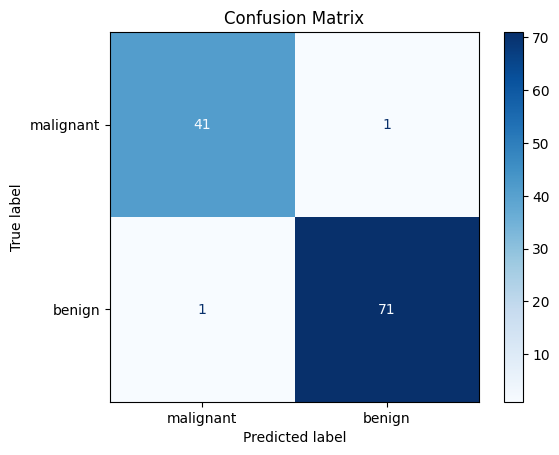

              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



In [2]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=data.target_names, cmap='Blues')
plt.title('Confusion Matrix')
plt.show()
print(classification_report(y_test, y_pred, target_names=data.target_names))

## Macro, weighted, and micro averages
- **Macro**: treats each class equally.
- **Weighted**: weights each class by its support.
- **Micro**: aggregates contributions across classes.

In [3]:
from sklearn.metrics import precision_score, recall_score, f1_score
for average in ['macro', 'weighted', 'micro']:
    print(average, 'precision:', round(precision_score(y_test, y_pred, average=average), 4), 'recall:', round(recall_score(y_test, y_pred, average=average), 4), 'F1:', round(f1_score(y_test, y_pred, average=average), 4))

macro precision: 0.9812 recall: 0.9812 F1: 0.9812
weighted precision: 0.9825 recall: 0.9825 F1: 0.9825
micro precision: 0.9825 recall: 0.9825 F1: 0.9825


## Key takeaways
Accuracy is the fraction of correct predictions. Precision measures the reliability of positive predictions; recall measures how many actual positives were found; F1 balances precision and recall. Choose metrics based on the costs of errors.